## Abstract

Placeholder. Write this last, in 280 characters or fewer. The framing depends on how Question 3 resolves.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on AirTable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Placeholder. This section will state why the work was done, the key takeaway, and who it is for.

The argument to make here: binder design campaigns run with ESMFold2 return mostly &alpha;-helical binders, and a designer who needs a different fold has no obvious knob to turn. We add a secondary-structure term to the design loss, show what it buys and what it costs, and report whether the resulting designs are worth trialing.

Primary audience: people running structure-prediction-based binder design campaigns, and people interested in what can be steered in a folding model after training.

## Introduction

Placeholder. Three claims to establish, each needing citations added to `ref.bib`:

1. **Binder design tends to be &alpha;-rich.** Design pipelines built on structure predictors return helical binders far more often than any other fold class. To write: how general this is across pipelines, and what is already known about why.
2. **Increasing structural diversity yields better campaigns.** A more structurally diverse design pool improves the odds that a campaign yields a binder that works experimentally. To write: the evidence for this, and how diversity is usually pursued today.
3. **Sometimes success is locked behind &beta;-rich designs.** Some epitopes are not addressable by a helical bundle. To write: concrete examples where a &beta;-rich binder was the one that worked.

These three claims motivate the three questions that structure the rest of the notebook.

:::{.callout-note collapse="true" title="Reproducing this notebook"}
**Nothing here is tracked in the repository, and nothing needs an account.** Both of this pub's inputs are deposited, and the notebook fetches what is missing on first execution: `make execute` downloads them from a public S3 bucket, falling back to [Zenodo](https://zenodo.org) if S3 is unreachable. The downloaded archive is kept beside the extracted data as the marker that says it arrived that way, so subsequent runs find it and skip straight to loading. `make preview` renders from the cached results in `_freeze/` and downloads nothing at all.

The two inputs are deposited for different reasons, and the difference is whether they can be derived.

**The natural binder reference set is derived here.** What the deposit holds is the *inputs*: the frozen RCSB search results and the gzipped structures. The notebook runs the analysis over them, measuring every chain with the same `analysis.secondary_structure` code that measures the designs. So the measurement is reproduced on every fresh clone rather than taken on trust. Recording the search results, not just the query, is also what pins the set: the RCSB recomputes its sequence-identity clusters as the PDB grows, so a live query drifts where a recorded one does not.

**The design campaigns are not derived here.** Designing needs GPUs and costs real money, and the loop is not seed-reproducible: across two runs of an identically configured arm, no seed reproduced its own result and per-seed interface pTM moved by 0.14 to 0.20. A rerun produces *different* designs rather than the same ones, so the deposit holds the finished per-design tables and the notebook reads them.

### Regenerating everything from source

```bash
modal deploy src/analysis/modal_app.py
FORCE_RERUN=1 make execute
```

`FORCE_RERUN=1` deletes every derivable file, skips the deposit entirely, queries the live RCSB, and designs all 450 binders again on [Modal](https://modal.com). It is checked for a Modal token *before* anything is deleted, so a missing account cannot leave you with neither the data nor the means to make it. The grid is five targets by three loss arms by thirty seeds at 150 optimization steps, which took 78 minutes at 30 concurrent H100s; `ESMFOLD2_SS_MAX_CONTAINERS` sets that concurrency and defaults to 30, so lower it to match your own quota. Unset `FORCE_RERUN` afterwards, or every later execution will delete and regenerate again.

Expect a regenerated run to reproduce the conclusions rather than the numbers. The designs will differ for the reason above, and the reference set may differ slightly because the live query re-clusters.
:::

In [1]:
#| include: false

import warnings

import pandas as pd
from analysis import (
    campaign,
    composition,
    deposit,
    figures,
    loss_trace,
    paths,
    reference,
    steering,
    targets,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
paths.ensure_dirs()

TARGETS = list(targets.TARGET_SPECS)
ARMS = list(targets.CAMPAIGN_ARMS)

In [2]:
#| include: false

if deposit.force_rerun():
    deposit.require_modal()
    removed = deposit.clear_generated()
    print(f"{deposit.FORCE_RERUN_ENV}=1: removed {len(removed)} generated paths")
    campaign.ensure(TARGETS, ARMS)
else:
    deposit.DESIGN_TABLES.fetch()

## ESMFold2 designs are biased towards &alpha;-helix

The ESMFold2 preprint demonstrates binder design on five targets: the EGFR domain III, the PDGFR&beta; D2&ndash;D3 tandem, the PD-L1 and CTLA-4 IgV domains, and the CD45 d3&ndash;d4 tandem. Those are the five used here. Running the algorithm unmodified against each, 30 designs per target at 150 optimization steps, gives 150 binders whose secondary structure can be measured directly from the predicted complex.

For a comparison set we queried the RCSB for experimentally determined heterodimers and kept the chains of 60&ndash;200 residues, the range the design loop samples binder lengths from. That gives 2,098 natural binder chains, each solved in complex with its partner. Short proteins are helix-biased on their own, so the natural set is resampled to match the length distribution of the designs rather than pooled across lengths.

@fig-composition sets the two side by side across the length range, in each of the three states.

In [3]:
#| include: false

natural = reference.composition()
designs = composition.load_all(TARGETS, ["vanilla"])
matched = reference.length_matched(
    natural, designs["binder length (residues)"], "binder_sample_length_residues"
)

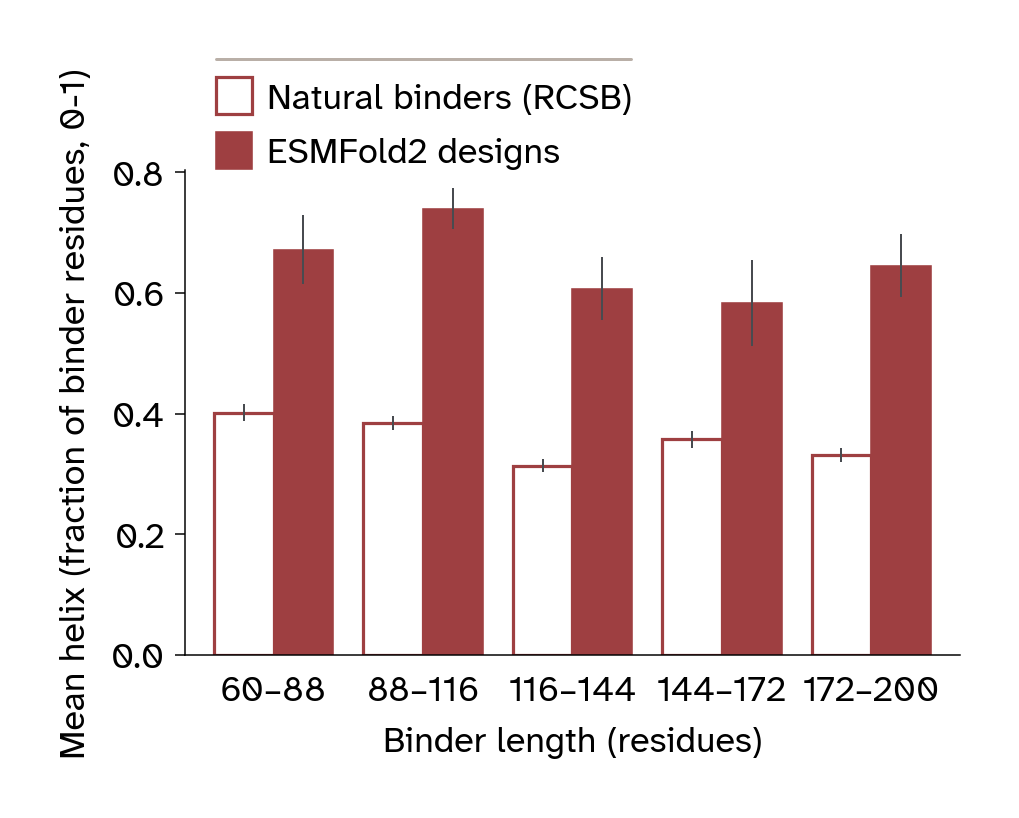

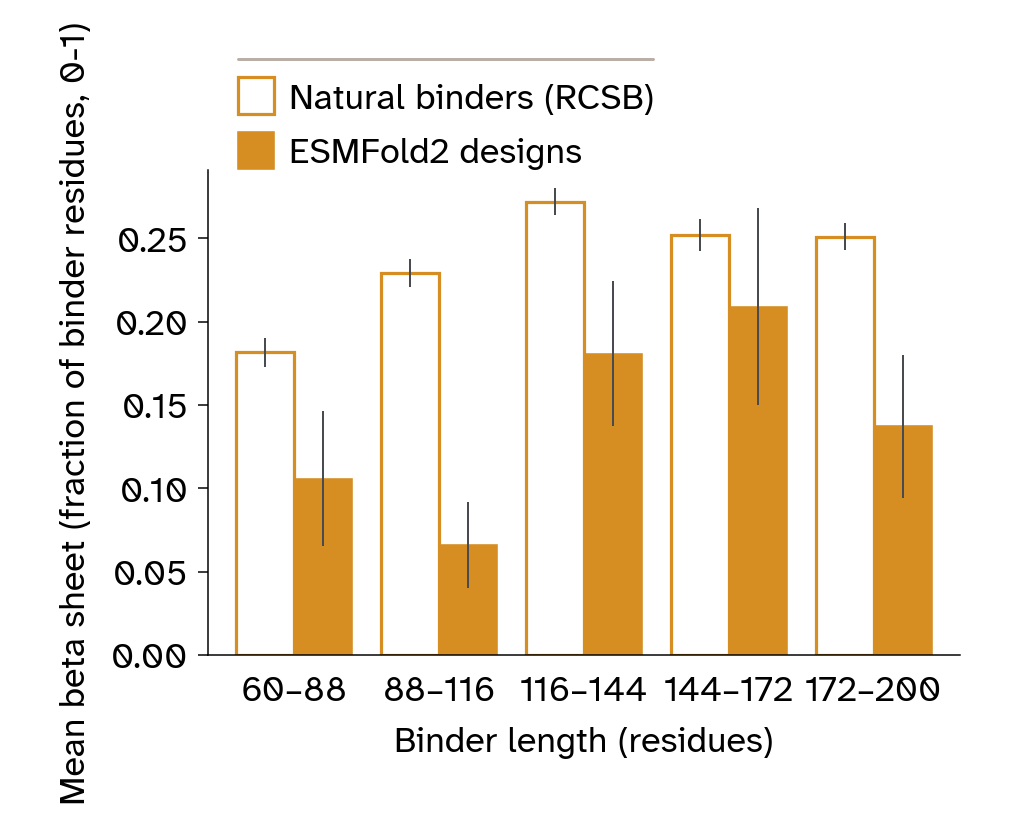

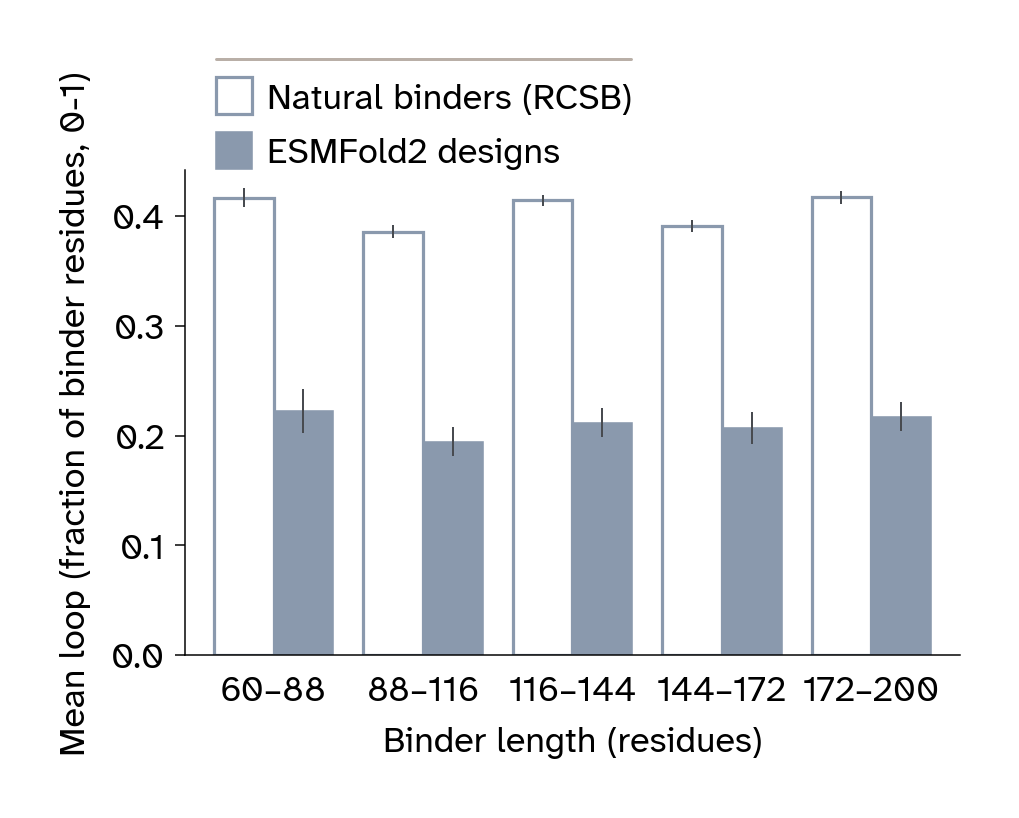

In [4]:
#| label: fig-composition
#| fig-cap: "Secondary-structure composition of ESMFold2 binder designs against natural binders of the same length. One colour per state; within each length bin the unfilled bar on the left is the natural reference and the filled bar on the right is the designs. Bars are means within five equally spaced binder-length bins, with standard-error whiskers. The reference whiskers are the small ones, since each reference bar rests on roughly 400 chains against 20 to 40 designs. The natural set is resampled to match the length distribution of the designs, so the two bars within a bin describe comparably sized proteins. Each panel scales its own y-axis, so bar heights are comparable within a panel but not across them."
#| fig-subcap:
#|   - "Helix"
#|   - "Beta sheet"
#|   - "Loop"
#| layout-ncol: 2
#| code-fold: true
#| code-summary: "Code for Figure 1"

for state in ("helix", "sheet", "loop"):
    figures.composition_bars(matched, designs, state)

The median design is **80% helix**, against **31%** for a length-matched natural binder; Cliff's delta is **+0.60**, above the conventional threshold for a large effect. The excess holds in every length bin of @fig-composition-1, so it is not an artifact of the designs and the natural set occupying different parts of the length range.

Sheet runs the other way. The median design contains **no sheet at all**, against 26% for the natural set, but that result needs calibrating before it can be read: a single &beta;-free binder is unremarkable, since **20% of natural binders in this length range also have zero sheet**. The difference is in how common it is, at **70% of designs**. The deficit holds in every bin of @fig-composition-2, though the design bars carry visibly wider standard errors than the natural ones: the designs that do form sheet form a lot of it, so a bin mean rests on a handful of high values against many zeros.

Loop shows the largest separation of the three, at Cliff's delta &minus;0.81: designs average 21% loop against 40% for natural binders, and @fig-composition-3 shows the gap in every bin. So the helix is displacing irregular structure as much as it is displacing sheet. This is also the panel most exposed to the confound described below, because predicted structures tend to have cleaner secondary structure than experimental ones, which would suppress loop specifically. It should be read as consistent with the helix result rather than as independent evidence for it.

The pattern holds on every target. Median helix ranges from 0.75 to 0.84 across the five, and median sheet is zero on all five, including the four whose own fold is entirely &beta;. The preference is therefore a property of the design procedure rather than a response to the target. Mean helix, 0.67, sits below the median, so a minority of designs are considerably less helical than the rest: this is a central tendency, not a floor.

:::{.callout-note collapse="true" title="How secondary structure is assigned, and what to distrust about the comparison"}
Labels come from [`pydssp`](https://github.com/ShintaroMinami/PyDSSP), a Kabsch&ndash;Sander implementation, collapsed to three states and reported as a fraction of binder residues. Both sides go through the same `analysis.secondary_structure` code, so the two are not measured by two different implementations of DSSP. Only residues with a complete N, C&alpha;, C and O backbone are labelled, so a residue missing from a model is missing from its denominator too.

The reference set comes from one RCSB query, recorded in `data/reference/natural_binder_search_hits.json` and rerunnable with `analysis.rcsb.build`: X-ray entries at 2.5 Å or better, exactly two polymer entities, heteromeric, a named source organism that is not "synthetic construct", and at least one entity of 60&ndash;200 residues, which is the range the design loop samples binder lengths from. Entities are clustered at 30% sequence identity and one representative per cluster is kept. That leaves 2,098 chains from 1,813 entries at median resolution 2.00 Å. Where both chains of an entry are in range, 53% of them, each takes its turn as the binder.

Now the things worth distrusting.

**"Binder" is a label we impose.** In a natural heterodimer neither chain is the binder; both are partners. Calling the 60&ndash;200-residue chain the binder is an analogy to the design setting, not a fact about the complex.

**Some partners are peptides, not domains.** Target chains run from 8 to 1,020 residues, and 15% are short enough to flag as peptide targets. A 100-residue protein gripping an 8-residue peptide is a different structural problem from a designed minibinder against a folded domain. These are flagged in the table rather than removed, so the flag can be used to test sensitivity.

**Some interfaces may not be real.** 13% are small enough to be crystal packing rather than function. Also flagged rather than removed.

**"Natural" is approximate.** 1% of binders and 3% of targets read as engineered scaffolds by description. Excluding "synthetic construct" as a source organism catches the obvious cases, not the subtle ones.

**The PDB is a convenience sample.** X-ray at 2.5 Å or better favours proteins that crystallise well, which favours compact, rigid, often &beta;-rich folds, and excludes cryo-EM and NMR entirely. 31% of binders are human. This is a sample of the binders that got solved, not of binders.

**Clustering at 30% identity does not remove structural redundancy.** Immunoglobulin-like folds recur across clusters that share little sequence.

**Composition is measured over resolved residues only**, a median 96% of each construct, which biases the natural coil fraction downward and makes the natural set look more ordered than the protein is in solution.

**The two sides sit on different kinds of coordinates.** The natural set is experimental; the designs are ESMFold2's own prediction, and predicted structures tend to have idealised secondary structure. That would inflate both helix *and* sheet in the designs, so it cannot explain a sheet deficit, but it does mean the coil comparison should be read loosely.
:::

## A loss term steers designs out of the &alpha;-rich basin

The intervention tested here is a term added to the objective a design run minimizes, so the loop and the objective it already carries come first.

In [5]:
#| include: false

steered = composition.load_all(TARGETS, ARMS)
trace = loss_trace.load_all(TARGETS, ARMS)

TARGET_ORDER = (
    steered[steered["arm"] == "helix_logcap_w02"]
    .groupby("target")["helix (fraction 0-1)"]
    .median()
    .sort_values()
    .index.tolist()
)

### How ESMFold2 designs a binder

Nothing about the model changes. Design is inference-time optimization: the weights of every network involved stay frozen, and the only thing that moves is the binder's own sequence. A run starts from the target sequence and a binder length drawn uniformly from 60 to 200 residues, and holds the binder's identity as a tensor of per-position amino-acid logits. The target is a fixed one-hot encoding that no gradient reaches.

Each of the 150 steps softmaxes those logits into a soft sequence, folds the target and the soft binder together with ESMFold2, and reads the predicted C&alpha;&ndash;C&alpha; distogram &mdash; a distribution over 128 distance bins for every residue pair. The objective is computed from that distogram, and its gradient is taken back through the folding stack to the logits. So the search is a structure-prediction model being run backwards: the thing being asked for is a sequence whose predicted structure scores well.

A sequence that satisfies a geometric objective need not look like a protein, so a second gradient comes from ESMC, scoring the binder's pseudo-perplexity under a masked-language model over four sampled mask passes. ESMC is the sequence prior rather than the search: it constrains what the structural objective is allowed to ask for. The two gradients are separately normalized to unit norm per position and summed in a 1 to 0.15 ratio, then applied by SGD. ESMC also sits inside ESMFold2 as its language-model trunk, and the two share those weights in memory.

The softmax temperature follows a cosine schedule from 1 down to 0.01, so early steps optimize a genuinely mixed sequence and late steps a nearly discrete one. Each step draws one of two ESMFold2 replicates at random.

When the run ends, the best sequence is refolded by four ESMFold2 critic models at higher sampling, and those critics supply every interface pTM and per-chain pLDDT quoted below. The critique is therefore an estimate from the same architecture that ran the search, at a different sampling budget. Question 3 is about what follows from that.

Across every arm in this section the target, the seed, the binder length, the step count, the learning rate, the temperature schedule and the critics are identical. The only thing that differs is the objective.

### The objective it already minimizes

Two of the three structural terms are contact terms, and both are built from the same quantity. For a residue pair $(i,j)$ with distogram logits $z_{ij}$ over bins at midpoints $d_b$, write $p_{ij}$ for the softmax over all bins and $\tilde{p}^{\,c}_{ij}$ for the softmax restricted to bins nearer than a cutoff $c$. The contact score is the cross-entropy between the two:

$$
H^{c}_{ij} \;=\; -\sum_{b} \tilde{p}^{\,c}_{ij}(b)\,\log p_{ij}(b)
$$

This is low when the pair's distance distribution already concentrates below $c$, and high when it does not, so minimizing it pulls a pair into contact. Each term then averages, over a set of rows $R$, the mean of the $k$ smallest such scores available in a set of columns $S$ at sequence separation at least $s$:

$$
\mathcal{C}(R, S, k, c, s) \;=\; \frac{1}{|R|}\sum_{i \in R} \operatorname*{mean}_{k\text{ smallest}} \big\{\, H^{c}_{ij} \;:\; j \in S,\; |i-j| \ge s \,\big\}
$$

$$
\mathcal{L}_{\mathrm{intra}} = \mathcal{C}(\text{binder},\, \text{binder},\, k{=}2,\, c{=}14\,\text{Å},\, s{=}9),
\qquad
\mathcal{L}_{\mathrm{inter}} = \mathcal{C}(\text{target},\, \text{binder},\, k{=}1,\, c{=}22\,\text{Å},\, s{=}0)
$$

The two differ in more than their constants. The intra term asks each binder residue for its two best non-local partners inside the binder, which is a request for a folded rather than extended chain. The inter term is averaged over the **target's** residues, each taking its single best partner on the binder, so it asks the binder to cover the target rather than asking the binder to find a foothold.

The third term is a globularity penalty. With $\hat{\mathbb{E}}[d_{ij}^2]$ the distogram's expected squared distance over binder pairs, capped at 27 Å per bin, and $n$ the binder length:

$$
R_g \;=\; \sqrt{\frac{1}{n^{2}}\sum_{i>j} \hat{\mathbb{E}}\big[d_{ij}^{2}\big]},
\qquad
\mathcal{L}_{\mathrm{glob}} \;=\; \mathrm{ELU}\big(R_g - 2.38\,n^{0.365}\big)
$$

which charges nothing while the binder is more compact than a packed protein of its length and rises once it is not. The three combine at fixed weights:

$$
\mathcal{L}_{\mathrm{struct}} \;=\; 0.5\,\mathcal{L}_{\mathrm{intra}} \;+\; 0.5\,\mathcal{L}_{\mathrm{inter}} \;+\; 0.2\,\mathcal{L}_{\mathrm{glob}}
$$

Read together, they ask for a compact chain that touches itself non-locally and covers the target. None of them mentions secondary structure. There is no term that prefers a helix, and equally no term that prefers anything else &mdash; which is what makes the helix excess in @fig-composition a property of something other than an explicit request.

That is also what makes it addressable. The objective is recomputed at every one of the 150 steps from a distogram that already contains the C&alpha;&ndash;C&alpha; distances separating a helix from a strand, and the whole path from that distogram back to the sequence is differentiable. So a fourth term can be added to $\mathcal{L}_{\mathrm{struct}}$ that reads helical geometry off the same tensor and charges for it. Whether that is enough to move designs out of the &alpha;-rich basin, and what it costs, is the rest of this section.

### The secondary-structure loss term

In an &alpha; helix the C&alpha; atoms of residues $i$ and $i{+}4$ sit about 6.2 &Aring; apart. That is the shortest description of a helix available in a distance map, and it is what the term measures.

Where the cookbook's contact terms score a pair by the cross-entropy $H^{c}_{ij}$, this one uses the plain near-bin mass: $q^{c}_{ij} = \sum_{d_b < c} p_{ij}(b)$, the probability that the pair is closer than $c$. Taking that at $c = 7$ &Aring; along the $i \to i{+}4$ diagonal gives a per-residue helicity, the twelve largest of which are averaged into one score $h$ for the binder. The loss is a clamped logarithmic barrier on it, added to the structural objective at a fixed weight $w$:

$$
h \;=\; \operatorname*{mean}_{\mathrm{top\text{-}12}\; i} q^{\,7\text{Å}}_{i,\,i+4},
\qquad
\mathcal{L}_{\mathrm{helix}} \;=\; \min\Big(-\log\big(\max(1-h,\,10^{-3})\big),\; 2\Big),
\qquad
\mathcal{L} \;=\; \mathcal{L}_{\mathrm{struct}} + w\,\mathcal{L}_{\mathrm{helix}}
$$

Three choices in that expression carry weight.

**It reads the distogram, not a secondary-structure label.** The composition reported in @fig-composition comes from DSSP, but DSSP cannot be optimized against: it needs backbone coordinates and returns a discrete class, and neither step carries a gradient. So the quantity steered and the quantity measured are deliberately not the same, and the term is only useful to the extent that pushing on one moves the other.

**It pools the top twelve rather than averaging over the binder.** A mean lets length dilute the signal: a 40-residue helix in a 200-residue design barely moves it. Twelve residues is about three helical turns, so $h$ tracks the most helical stretch present rather than the overall tendency.

**The barrier is clamped at 2.** The unclamped $-\log(1-h)$ grows without bound as $h$ approaches 1, which is what lets a small weight fight a helix that has already formed &mdash; a linear penalty on $h$ is bounded by 1 and loses to the contact terms once the helix is there. But unclamped at weight 0.2 it pulled harder late in a run than a linear penalty did at 0.5, and interface confidence went with it. The clamp keeps the mid-range shape and drops the late punch.

That clamp has a consequence the next section turns out to rest on: above $h = 1 - e^{-2} = 0.865$ the term is constant, so it contributes no gradient at all.

Six other terms were written and searched before this one, three further helix formulations and three sheet rewards. The sheet rewards never moved composition at any weight tried.

### Steering works

The term was applied at a constant weight of 0.2 and of 0.5 for all 150 steps, against an unsteered arm carrying it at weight zero. Thirty seeds per target per arm; because the binder length is drawn from the seed, each seed contributes the same binder length to all three arms.

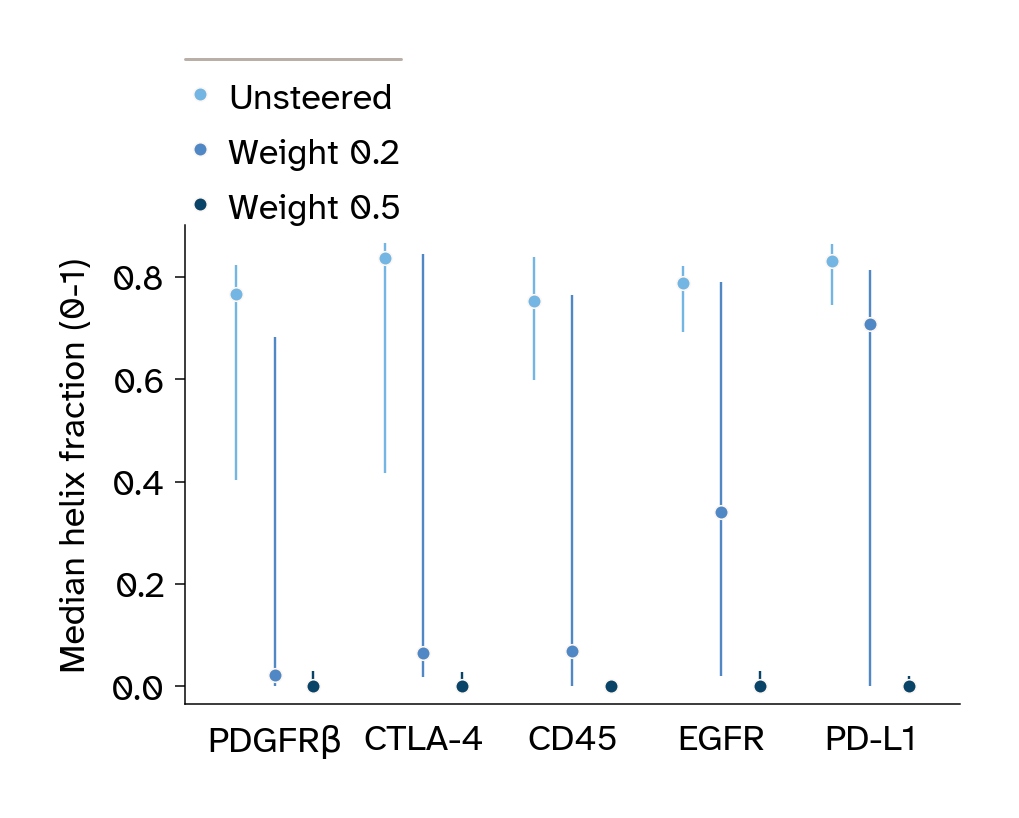

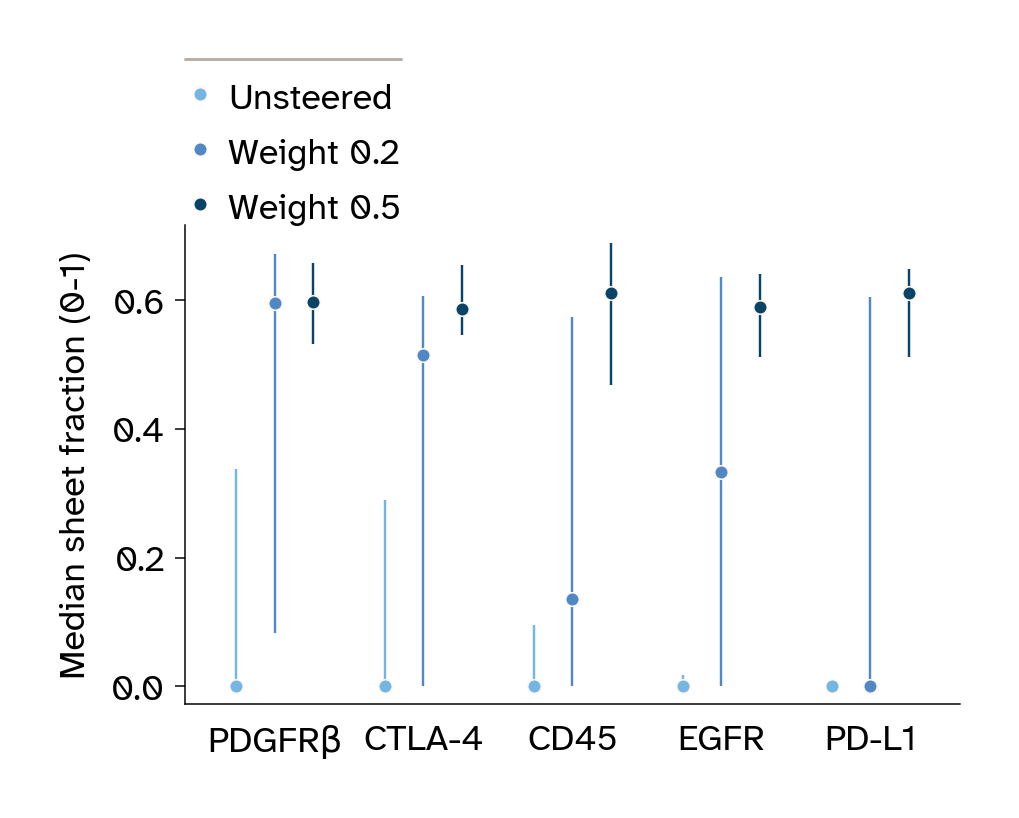

In [6]:
#| label: fig-steering
#| fig-cap: "Binder composition against steering weight. Each dot is the median over 30 designs and the whiskers span the interquartile range. Dots rather than bars because two of the four quantities plotted in this section do not have a meaningful zero; medians rather than means because helix fraction under steering is bimodal and sheet fraction is zero-inflated. Targets are ordered by how much helix survives at weight 0.2, and the panels share that order."
#| fig-subcap:
#|   - "Helix"
#|   - "Beta sheet"
#| layout-ncol: 2
#| code-fold: true
#| code-summary: "Code for Figure 2"

for metric in ("helix", "sheet"):
    figures.steering_dots(steered, metric, TARGET_ORDER, ARMS)

At weight 0.5 the outcome is the same on all five targets. Median helix falls from between 0.753 and 0.837 to exactly zero in @fig-steering-1, and median sheet rises from exactly zero to between 0.587 and 0.612 in @fig-steering-2. Paired by seed against the unsteered arm, the helix reduction is already significant on every target at weight 0.2, with Wilcoxon $p$ between $3.8 \times 10^{-6}$ and $7.5 \times 10^{-4}$.

Weight 0.2 is where the targets stop agreeing. On PDGFR&beta;, CTLA-4 and CD45 it does most of what 0.5 does, leaving median helix between 0.023 and 0.070. On EGFR it leaves 0.340, and on PD-L1 it leaves 0.707 &mdash; barely steered at the weight that nearly empties the other three. On all five the interquartile whiskers at this weight run from at most 0.02 up to above 0.68, so a design at weight 0.2 either leaves the basin or stays in it, and the median reports which way most of them went rather than a typical amount of helix.

Across all 450 designs the helix that steering removes is replaced about seven-tenths by sheet and three-tenths by loop: mean helix falls 0.605, mean sheet rises 0.421, mean loop rises 0.184.

### When the fold is decided, and which targets resist

Every steering term is measured at every step of every run, including runs that carry no steering weight, so $h$ is available as a trajectory and not only as an outcome. There are 67,500 such step records across the grid.

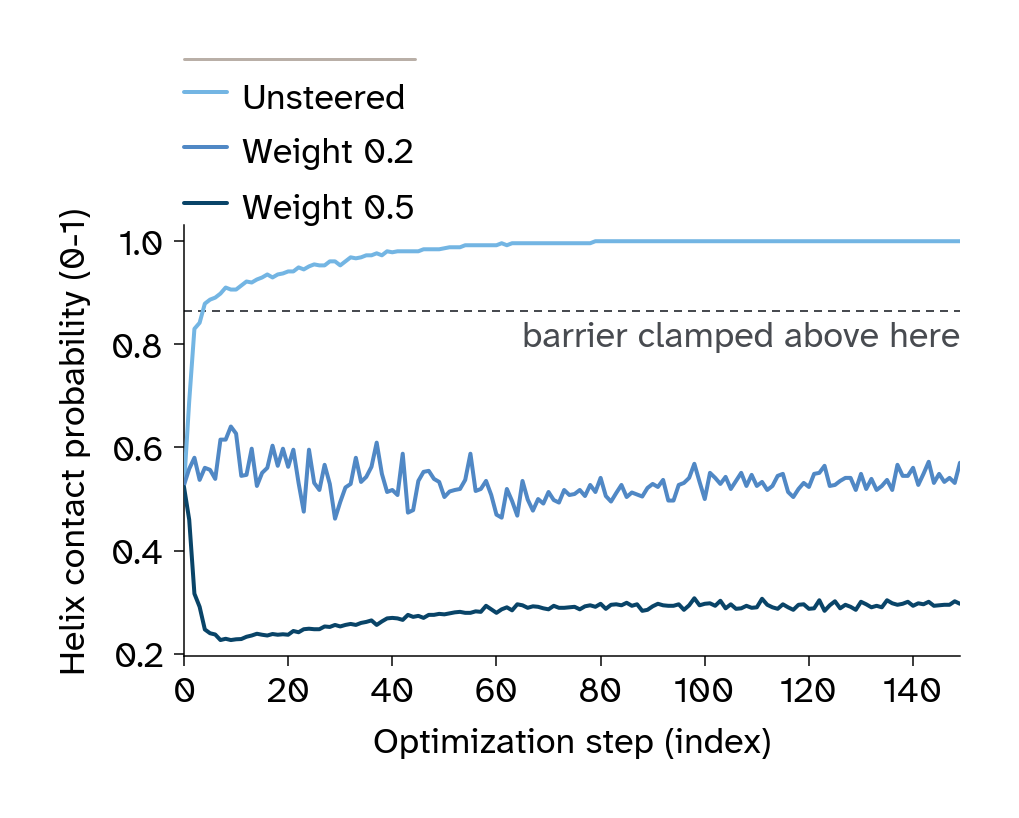

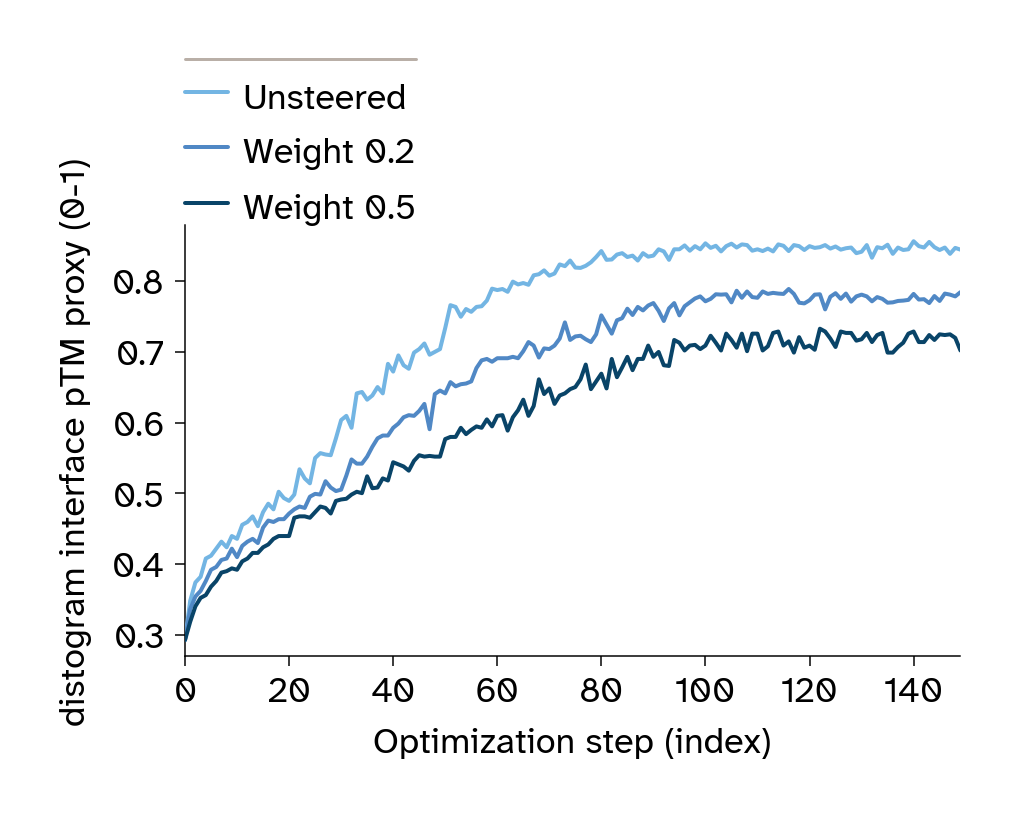

In [7]:
#| label: fig-trace
#| fig-cap: "The optimization trajectory, per arm. Lines are the per-step median across all 150 designs in an arm; no spread band, because the three interquartile ranges overlap across most of the run and drawing them hid the lines they belonged to. The left panel is the helicity score the steering term acts on, with the clamp threshold marked; the right panel is the per-step interface confidence proxy, which is available at every step where true interface pTM is not."
#| fig-subcap:
#|   - "Helicity score the term acts on"
#|   - "Interface confidence proxy"
#| layout-ncol: 2
#| code-fold: true
#| code-summary: "Code for Figure 3"

for metric in ("helix_contact", "iptm_proxy"):
    figures.trace_lines(trace, metric, ARMS)

In @fig-trace-1 all three arms start at $h \approx 0.52$, which is the initialization rather than a result. The unsteered arm is above the clamp threshold by step 4 and saturated at $h = 1$ by step 60. Weight 0.5 reaches $h \approx 0.23$ by step 5 and stays there. Weight 0.2 settles around 0.55.

The fold class is therefore decided within the first handful of steps out of 150, and then held. Interface confidence is not: in @fig-trace-2 the proxy climbs until roughly step 100 in every arm. The gap between the unsteered arm and weight 0.5 widens to 0.178 by step 60 and then stops widening, closing slightly to 0.143 by the end. The confidence cost is paid alongside the fold decision, early, rather than accumulated across the run.

The clamp is what decides which targets resist. Above $h = 0.865$ the barrier is flat, so a design already in that region gets no gradient from it, and the weight has to be large enough to push $h$ below the threshold before the term can act at all.

In [8]:
#| label: tbl-clamp
#| tbl-cap: "How often the steering term is gradient-dead, as the share of optimization steps spent above the clamp threshold, alongside the helicity score held over the last third of the run."
#| code-fold: true
#| code-summary: "Code for Table 1"

dead = trace.assign(
    dead=trace["helix_penalty (0-1)"] > steering.CLAMP_CONTACT_PROBABILITY
)
late = dead[dead["step (index)"] >= 100]

shares = (
    100 * dead.pivot_table(index="target", columns="arm", values="dead", aggfunc="mean")
)[ARMS].round(1)
shares.columns = [f"dead steps, {figures.ARM_LABELS[a].lower()} (%)" for a in ARMS]

scores = late.pivot_table(
    index="target", columns="arm", values="helix_penalty (0-1)", aggfunc="median"
)[ARMS].round(3)
scores.columns = [f"late h, {figures.ARM_LABELS[a].lower()} (0-1)" for a in ARMS]

shares.join(scores).loc[TARGET_ORDER]

,"dead steps, unsteered (%)","dead steps, weight 0.2 (%)","dead steps, weight 0.5 (%)","late h, unsteered (0-1)","late h, weight 0.2 (0-1)","late h, weight 0.5 (0-1)"
target,,,,,,
pdgfrb_d2d3,83.7,30.3,6.5,1.0,0.412,0.260
ctla4_igv,86.5,42.5,3.5,1.0,0.516,0.320
cd45_d3d4,88.8,40.1,0.0,1.0,0.588,0.277
egfr_d3,92.5,47.4,9.7,1.0,0.785,0.314
pdl1_igv,88.5,52.2,6.6,1.0,0.988,0.309


In @tbl-clamp, PD-L1 spends more than half of its weight-0.2 steps in the dead region, and its median $h$ over the last third of the run is 0.988, above the clamp for effectively the whole campaign. Across the five targets the share of gradient-dead steps at weight 0.2 orders them almost exactly as the surviving helix does &mdash; Spearman $\rho$ = 0.90, with CD45 and CTLA-4 swapping &mdash; though on five points that describes the ordering rather than establishing it. At weight 0.5 no target spends more than a tenth of its steps saturated, and all five finish with no helix.

### The cost: interface confidence suffers

Both confidence readouts fall as the weight rises, and unlike the composition response the size of the fall is strongly target-specific.

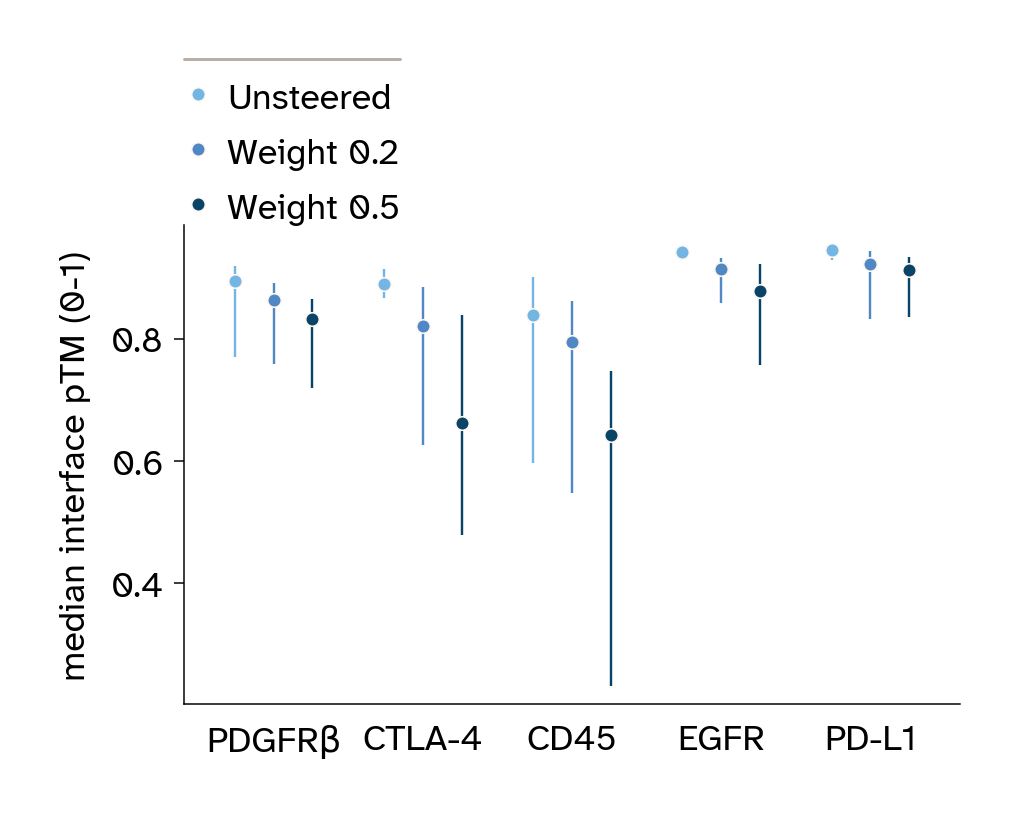

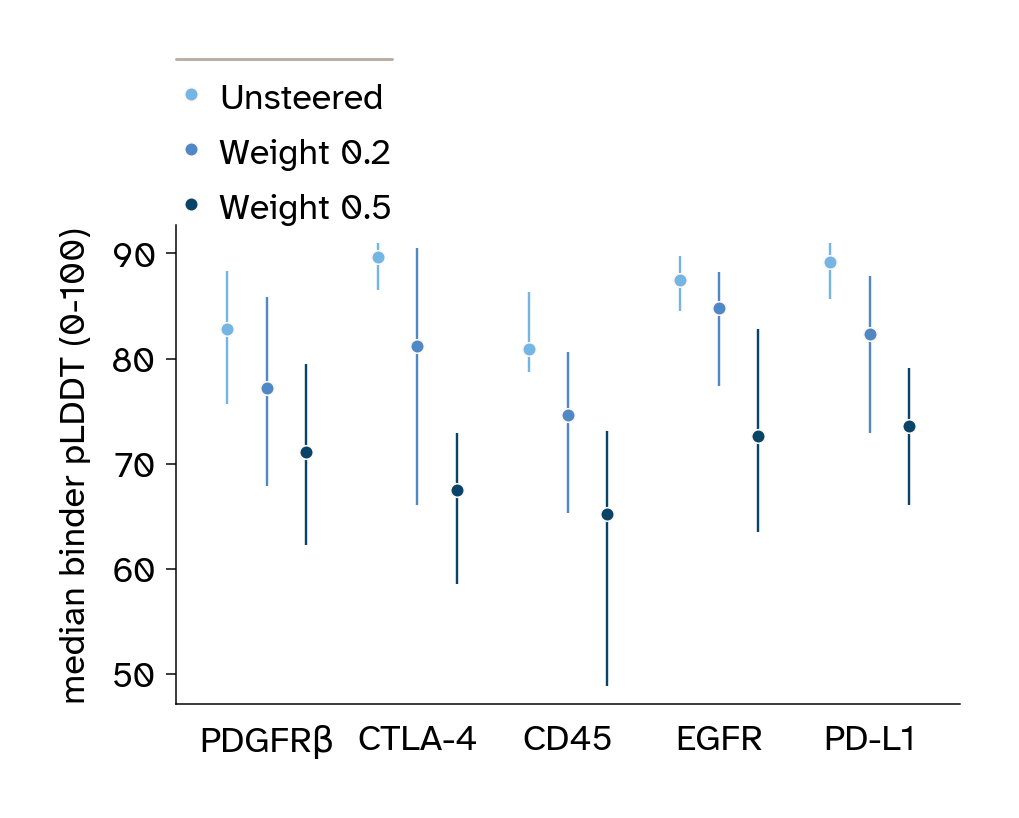

In [9]:
#| label: fig-cost
#| fig-cap: "Interface confidence against steering weight, on the same targets and in the same order as @fig-steering. Dots are medians over 30 designs with interquartile whiskers. Both quantities come from the critic models refolding the finished sequence, not from the design loop."
#| fig-subcap:
#|   - "Interface pTM"
#|   - "Binder pLDDT"
#| layout-ncol: 2
#| code-fold: true
#| code-summary: "Code for Figure 4"

for metric in ("iptm", "plddt"):
    figures.steering_dots(steered, metric, TARGET_ORDER, ARMS)

In [10]:
#| label: tbl-cost
#| tbl-cap: "Median interface pTM and binder pLDDT per target and arm."
#| code-fold: true
#| code-summary: "Code for Table 2"

pd.pivot_table(
    steered,
    index="target",
    columns="arm",
    values=["iptm (0-1)", "binder pLDDT (0-100)"],
    aggfunc="median",
).round(2)[[
    ("iptm (0-1)", arm) for arm in ARMS
] + [
    ("binder pLDDT (0-100)", arm) for arm in ARMS
]].loc[TARGET_ORDER]

iptm (0-1)                                   binder pLDDT (0-100)  \
arm            vanilla helix_logcap_w02 helix_logcap_w05              vanilla   
target                                                                          
pdgfrb_d2d3       0.89             0.86             0.83                82.86   
ctla4_igv         0.89             0.82             0.66                89.68   
cd45_d3d4         0.84             0.80             0.64                80.93   
egfr_d3           0.94             0.91             0.88                87.50   
pdl1_igv          0.95             0.92             0.91                89.16   

                                               
arm         helix_logcap_w02 helix_logcap_w05  
target                                         
pdgfrb_d2d3            77.24            71.15  
ctla4_igv              81.23            67.54  
cd45_d3d4              74.66            65.19  
egfr_d3                84.85            72.65  
pdl1_igv               82.39            73.62

At weight 0.5 the median interface pTM drop in @fig-cost-1 ranges from 0.033 on PD-L1 to 0.228 on CTLA-4, a factor of seven across five targets at one weight. Binder pLDDT in @fig-cost-2 falls by between 11.7 and 22.2 points over the same comparison. @tbl-cost gives both per target. Pooled, median interface pTM runs 0.914, 0.864, 0.791 across the three arms and median binder pLDDT 87.2, 80.3, 68.8.

Whether that is worth paying depends on what a design has to clear. Under the viability rule used here &mdash; helix below 0.20, sheet at least 0.15, interface pTM at least 0.70 and binder pLDDT at least 70, all at once &mdash; steering gains more designs than the confidence cost removes: 8 of 150 unsteered designs are viable, against 41 at weight 0.2 and 55 at weight 0.5.

Which of the two weights is better follows the same target-specific pattern as the composition response. Weight 0.5 beats 0.2 on PD-L1 by 11 seeds to 1, exact McNemar $p$ = 0.006 &mdash; the target the lower weight could not move. Pooled over the other four it is 20 to 16, $p$ = 0.618. There is no single weight to recommend here: the one that works is whichever is large enough to carry a given target past the clamp without costing more confidence than that target can spare.

A fall in a confidence metric is not by itself a fall in design quality, and the models scoring these designs share an architecture with the model being steered. Question 3 is where that is examined.

## Question 3: Is it model bias?

Placeholder, and the one section whose answer is not yet known. **These experiments have not run.** Nothing below should be read as a result.

The question: when a steered, &beta;-richer design scores poorly on interface confidence, is that because the design is genuinely worse, or because ESMFold2 systematically assigns lower confidence to &beta;-rich structures regardless of their quality?

The planned test: score reference structures of known quality from the RCSB, spanning a range of secondary-structure composition, and ask whether the model's confidence tracks fold class on structures that are known to be real.

Figure 5 goes in the cell below: model confidence versus secondary-structure composition (fraction of residues, 0&ndash;1) across the RCSB reference set.

The two branches, to be resolved by the experiment, not by writing:

- **If yes, it is model bias.** The confidence penalty on &beta;-rich designs is at least partly an artifact, the steered designs are not as bad as their scores suggest, and the takeaway is that they are worth trialing experimentally.
- **If no.** The confidence drop reflects genuinely poorer designs, and the takeaway shifts to the fraction of steered designs that clear a viability bar anyway, and to how much steering can be applied before that fraction collapses.

In [11]:
print("Question 3 has not been run.")
print("Two problems are recorded in the project notes and must be resolved first:")
print("  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.")
print("  2. The readout adds Calpha RMSD of the refold against deposited coordinates.")

Question 3 has not been run.
Two problems are recorded in the project notes and must be resolved first:
  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.
  2. The readout adds Calpha RMSD of the refold against deposited coordinates.


## Takeaways

Placeholder for the summary, which branches on Question 3 and so cannot be written yet. The two sections after it do not depend on that answer.

### Summary

Placeholder. Two or three sentences: basal &alpha;-richness is high, a loss term steers away from it, interface confidence pays for it, and Question 3 decides whether that payment is real. Write this after Question 3 resolves.

### A loss term is a tuning handle, and secondary structure is one thing to tune

The steering result matters less for what it does to helices than for what it says about the method. A differentiable term added to the design loss changed the fold class of the output without retraining anything and without touching the model weights. The handle is the distogram the design loop already optimizes against, and it was sitting there unused.

That reframes the contribution. This is not a paper about helices. It is a worked example of adding a constraint to ESMFold2's binder design algorithm, with the measurements needed to say honestly what the constraint bought and what it cost.

The limits we ran into are part of the example, and they generalize:

- The term stops acting once the property it penalizes is already saturated, so **when** a term applies during the run matters as much as how strongly.
- Pushing harder on one property costs confidence in another, so any added term needs its tradeoff mapped rather than asserted.
- The optimizer will satisfy a loss the cheapest way available, which is not always the way you intended.

Anyone adding a term to this design loop should expect all three.

### A binder is the start of a drug program, not the end

Nothing in this work produces a therapeutic. A design that binds its target with good predicted confidence has cleared the first of many gates. Downstream, a candidate still has to be developable: expressible and soluble at concentration, stable on the shelf, non-aggregating, humanized or otherwise non-immunogenic, free of manufacturing and post-translational liabilities, and specific enough not to bind everything else in the proteome.

Each of those is a property of a sequence or a structure. That is the interesting part, because it is the same kind of object the secondary-structure term acts on. In principle every one of them is expressible as a term on the distogram or on the sequence logits, and added to the same objective in the same place.

Sequence liabilities are the nearest example, and one worth tuning rather than ignoring. Steering the fold also changes the sequences that come out, so a term that optimizes structure alone can quietly degrade a property nobody was watching. We did not write a liability term here, and the designs in this work should not be read as developable. Adding one is the obvious next thing to try, and it would test whether the tuning handle generalizes beyond the property we happened to pick.

That is the claim we want to leave the reader with: ESMFold2's binder design algorithm exposes a place to put constraints, secondary structure is one constraint that demonstrably works there, and the constraints a drug program actually cares about are the reason to care.

## Next steps

Placeholder. What we would do next, and what someone else could pick up. Fill in once the takeaways are settled.

## An open question: objective or weights?

Everything here changes behavior without changing the model. The steering happens in the design loop, on top of frozen weights, and that is worth naming as a choice rather than a default, because there is an obvious alternative: retrain or fine-tune so that the model produces the distribution you want natively.

The two routes are not equivalent, and our results show some of the difference. Steering from the objective fights the model's prior instead of altering it, which may be why interface confidence pays a price, and why the optimizer sometimes satisfies the term in ways we did not intend. A model whose weights had learned the target distribution would presumably not need to be argued with in the same way.

But the comparison is lopsided on cost. Adding a term to the loss is a few lines and a single campaign. Retraining a structure prediction model of this scale means substantial compute, a training corpus assembled for the property you want, and revalidation of everything the base model was already good at, with the risk of degrading it. For a property you might only want occasionally, or want in three mutually exclusive variants, that is a steep price. Post-hoc terms are also composable, inspectable, and trivially reversible, which weight updates are not.

So we would pose it as a question rather than answer it. Which behaviors belong in the weights, and which belong in the objective? Is there a principled boundary, drawn perhaps by how fundamental a property is or how often it is wanted, or is the line mostly economic and therefore likely to move as training costs fall? We do not know, and the honest position from this work is that the objective route is cheap enough to be worth exhausting before anyone reaches for the weights.